In [1]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '0'
os.environ['TF_DETERMINISTIC_OPS'] = '1'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load
from scipy.signal import savgol_filter, welch, butter, filtfilt
from scipy.ndimage import gaussian_filter
from numpy import cos, sin
import joblib

In [2]:
def set_seed(seed):
    keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()

In [3]:
def def_parametros():
    parametros = [
            "TIME",        "TEMPO_SAD",        "EVENTO",        "HH",        "MM",        "SS",        "MSS",        "TOT",        "ALFAG",        "BETAG",
            "DL",        "DM",        "DN",        "DF",        "NX",        "NY",        "NZ",        "P",        "Q",        "R",        "PB",        "PB1",
            "QB",        "QB1",        "TI",        "T5_C",        "TETAL",        "FIL",        "CID",        "NG",        "PSI",        "PBEX",        "PIX",
            "PIY",        "VB",        "VB1",        "ZPB",        "ZPB1",        "W",        "pa",        "qc",        "Zp",        "Vc",        "Mach",
            "Ta_C",        "Va",        "Alfa",        "Beta",        "Ta_K",        "T",        "No. OBS."
    ]
    return parametros

In [4]:
def butter_lowpass(signal, cutoff_period_s, fs=1.0, order=1):
    cutoff_freq = 1.0 / cutoff_period_s
    nyq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

In [5]:
def parametros_adicionais(df):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Pa0 = 1013.25
    df['delta'] = df['pa']/Pa0
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    df['Mach2'] = df['Mach']**2

    df['Va2'] = df['Va']**2

    S = 19.3

    df['NX_filtered'] = butter_lowpass(df['NX'], cutoff_period_s=15)
    df['NZ_filtered'] = butter_lowpass(df['NZ'], cutoff_period_s=15)
    df['Alfa_filtered'] = butter_lowpass(df['Alfa'], cutoff_period_s=30)
    df['Va_filtered'] = butter_lowpass(df['Va'], cutoff_period_s=30)
    df['Hdot'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))*df['Va_filtered'] # Hdot em m/s
    df['Hdot_V'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))

    df['Hdot_W_V_dlt'] = (df['NX']*np.cos(np.radians(df['Alfa'])) + df['NZ']*np.sin(np.radians(df['Alfa'])))*df['W']/df['delta'] # (Hdot/V) * (W/delta), em kgf

    df['NZ_W_dlt'] = df['NZ']*df['W']/df['delta']
    df['NZ_W_dlt_sqr'] = df['NZ_W_dlt']**2

    # Filtro para cortar dados irrelevantes:
    df = df[df['Va_filtered'] > 90]
    df = df[df['Zp'] > 3000]

    return df

In [6]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
    else:
        files = ['039_2013_VIN_FND']

    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
    parametros = def_parametros()
    all_dfs = []
    for file in files:
        data = loadmat(local + file + '.mat')
        df = pd.DataFrame(data['DADOS'])
        df.columns = parametros
        df['filename'] = file
        all_dfs.append(df)
    df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df)

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['filename'].str.contains('039'), 'faixa_altitude'] = 'A'
        df.loc[df['filename'].str.contains('040'), 'faixa_altitude'] = 'B'
        df.loc[df['filename'].str.contains('041'), 'faixa_altitude'] = 'C'
        df.loc[df['filename'].str.contains('042'), 'faixa_altitude'] = 'D'
    else:
        df.loc[(df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 52625), 'faixa_altitude'] = 'A'
        df.loc[(df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53200), 'faixa_altitude'] = 'B'
        df.loc[(df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54075), 'faixa_altitude'] = 'C'
        df.loc[(df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55100), 'faixa_altitude'] = 'D'

    return df

-13.585768869018555
139.93421232910157


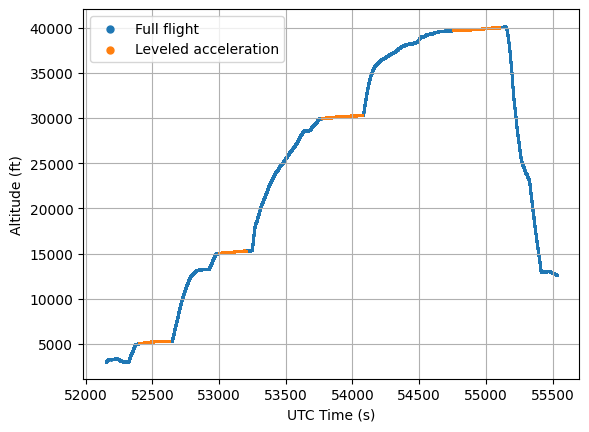

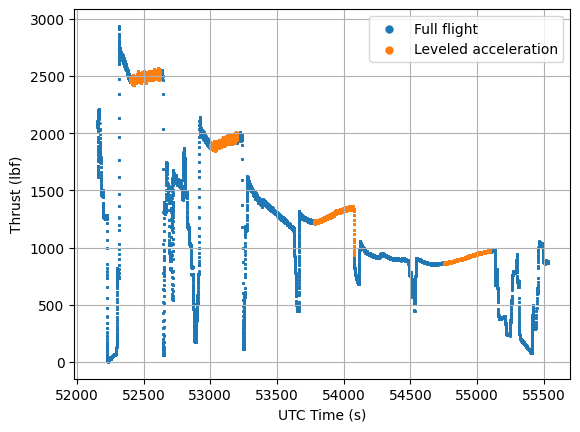

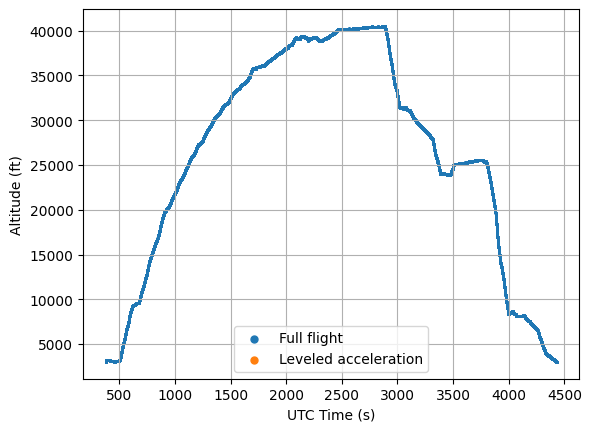

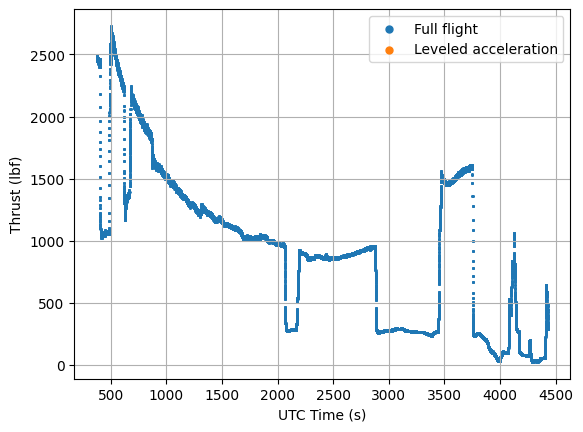

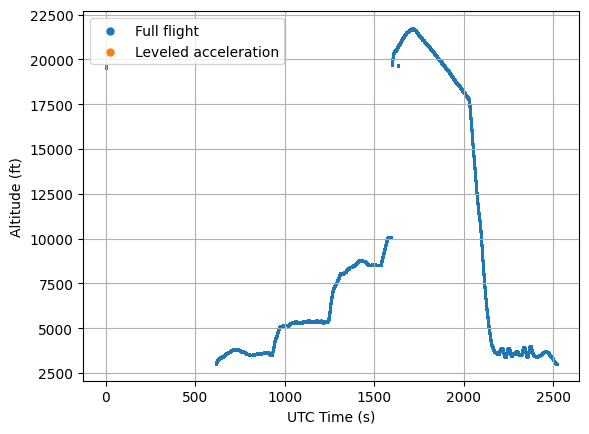

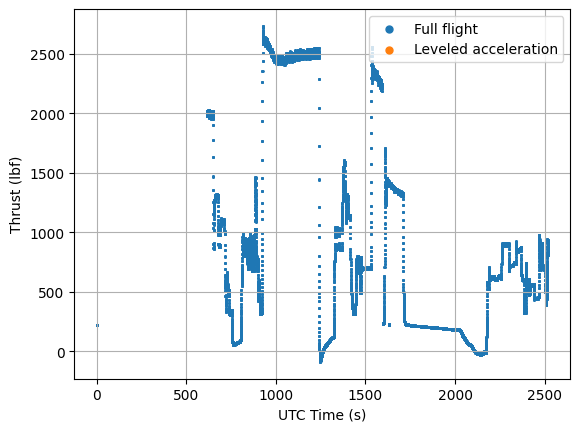

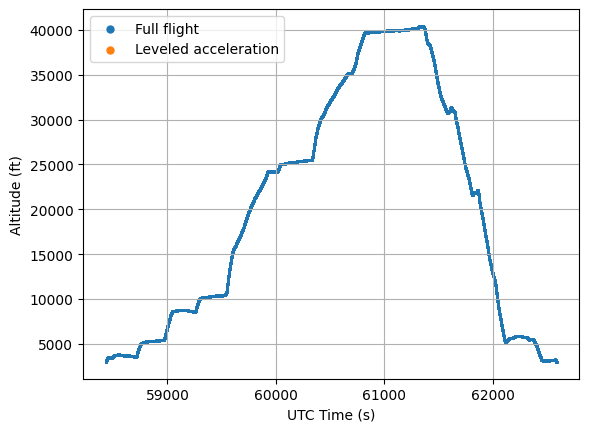

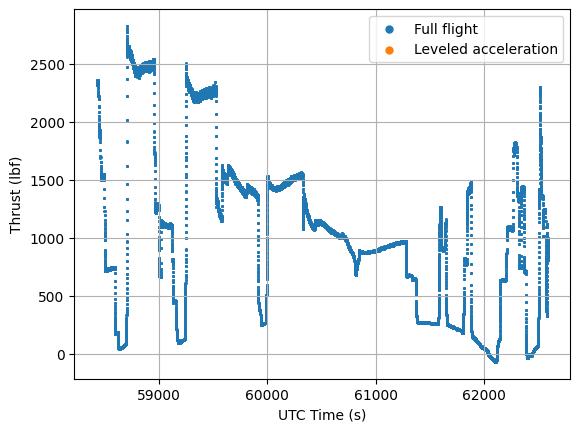

In [7]:
df = make_df('completo')
evaluated_set = 'train'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

# subset = df[df['type'] == evaluated_set]

print(df['Alfa'].min())
print(df['Alfa'].max())

for filename, grupo in df.groupby('filename'):
    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    mask_leveled_acceleration = (
        ((grupo['TEMPO_SAD'] > 52400) & (grupo['TEMPO_SAD'] < 52625)) +
        ((grupo['TEMPO_SAD'] > 53000) & (grupo['TEMPO_SAD'] < 53200)) +
        ((grupo['TEMPO_SAD'] > 53775) & (grupo['TEMPO_SAD'] < 54075)) +
        ((grupo['TEMPO_SAD'] > 54750) & (grupo['TEMPO_SAD'] < 55100))
    )
    grupo_aceleracao_nivelada = grupo[mask_leveled_acceleration]
    grupo = grupo[mask]


    # plt.title('Comparação de Hdot_W_V_dlt Real vs. Predito')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Zp'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['Zp'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Altitude (ft)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

    plt.scatter(grupo['TEMPO_SAD'], grupo['T'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['T'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Thrust (lbf)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

In [8]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [9]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    # for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
    #     mask = df['type'] == split
    #     df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
    #     df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
    #     # df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])
    #     df.loc[mask, [p+'_scaled' for p in colsy]] = df.loc[mask, colsy].values  # sem escalonamento
    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [10]:
import tensorflow as tf

class PMGModel(keras.Model):
    def __init__(self, main_model, z1_model, ng_index, lambda_mono=1.0, lambda_anchor=0.0, **kwargs):
        super().__init__(**kwargs)
        self.main_model = main_model
        self.z1_model = z1_model
        self.ng_index = ng_index
        self.lambda_mono = lambda_mono
        self.lambda_anchor = lambda_anchor
        self.penalty_tracker = keras.metrics.Mean(name='mono_penalty')
        self.anchor_tracker = keras.metrics.Mean(name='anchor_penalty')
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')

    def call(self, inputs, training=False):
        return self.main_model(inputs, training=training)

    @property
    def metrics(self):
        return super().metrics + [self.penalty_tracker, self.anchor_tracker, self.total_loss_tracker]

    def _physics_terms(self, x1, training):
        """Calcula a penalidade de monotonicidade e reaproveita o mesmo forward
        pass de NN1 (z1) para a penalidade de ancoragem — evita chamar z1_model
        mais de uma vez por passo de treino."""
        precisa_z1 = (self.ng_index is not None and self.lambda_mono != 0) or (self.lambda_anchor != 0)
        if not precisa_z1:
            return tf.constant(0.0), None

        with tf.GradientTape() as tape_phys:
            tape_phys.watch(x1)
            z1 = self.z1_model(x1, training=training)

        if self.ng_index is not None and self.lambda_mono != 0:
            dz1_dx1 = tape_phys.gradient(z1, x1)
            dz1_dng = dz1_dx1[:, self.ng_index]
            mono_penalty = tf.reduce_mean(tf.nn.relu(-dz1_dng))
        else:
            mono_penalty = tf.constant(0.0)

        return mono_penalty, z1

    def _anchor_penalty(self, z1, anchor_target, anchor_mask):
        """Penaliza |Z1 - anchor_target|^2, só nos pontos com anchor_mask == 1
        (ex.: 1% dos pontos de treino, ancorados em Tn_dlt)."""
        if self.lambda_anchor == 0 or z1 is None:
            return tf.constant(0.0)
        erro2 = tf.square(z1[:, 0] - anchor_target) * anchor_mask
        n_ativos = tf.reduce_sum(anchor_mask)
        return tf.reduce_sum(erro2) / (n_ativos + 1e-8)

    def train_step(self, data):
        x, y = data
        x1, x2, anchor_target, anchor_mask = x
        with tf.GradientTape() as tape:
            mono_penalty, z1 = self._physics_terms(x1, training=True)
            anchor_penalty = self._anchor_penalty(z1, anchor_target, anchor_mask)
            y_pred = self.main_model([x1, x2], training=True)
            data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
            total_loss = data_loss + self.lambda_mono * mono_penalty + self.lambda_anchor * anchor_penalty

        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

        self.penalty_tracker.update_state(mono_penalty)
        self.anchor_tracker.update_state(anchor_penalty)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)
            elif metric.name not in ('mono_penalty', 'anchor_penalty', 'total_loss'):
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x, y = data
        x1, x2, anchor_target, anchor_mask = x
        y_pred = self.main_model([x1, x2], training=False)
        data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
        mono_penalty, z1 = self._physics_terms(x1, training=False)
        anchor_penalty = self._anchor_penalty(z1, anchor_target, anchor_mask)
        total_loss = data_loss + self.lambda_mono * mono_penalty + self.lambda_anchor * anchor_penalty

        self.penalty_tracker.update_state(mono_penalty)
        self.anchor_tracker.update_state(anchor_penalty)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)
            elif metric.name not in ('mono_penalty', 'anchor_penalty', 'total_loss'):
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

In [11]:
def build_model(features1, features2, architecture={}, hyperparameters={}):
    neurons          = architecture.get('neurons', 32)
    n_hidden         = architecture.get('camadas_ocultas', 2)
    activation       = architecture.get('activation', 'relu')
    dropout_rate     = architecture.get('dropout', 0.0)

    optimizer_name   = hyperparameters.get('optimizer', 'adam')
    learning_rate    = hyperparameters.get('learning_rate', 0.001)
    epochs           = hyperparameters.get('epochs', 100)
    batch_size       = hyperparameters.get('batch_size', 32)
    patience         = hyperparameters.get('patience', 3)

    def build_subnetwork(input_tensor, name_prefix):
        x = input_tensor
        for i in range(n_hidden):
            x = layers.Dense(
                neurons,
                activation=activation,
                name=f'{name_prefix}_hidden_{i+1}'
            )(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'{name_prefix}_dropout_{i+1}')(x)
        z = layers.Dense(1, activation='softplus', name=f'{name_prefix}_output')(x)
        return z

    input_x1 = layers.Input(shape=(len(features1),), name='Entrada_X1')
    input_x2 = layers.Input(shape=(len(features2),), name='Entrada_X2')

    z1 = build_subnetwork(input_x1, name_prefix='NN1')
    z2 = build_subnetwork(input_x2, name_prefix='NN2')

    output = layers.Subtract(name='Saida_Y')([z1, z2])

    functional_model = Model(inputs=[input_x1, input_x2], outputs=output)
    z1_model = Model(inputs=input_x1, outputs=z1, name='Z1_extractor')

    mono_feature = hyperparameters.get('mono_feature', 'N1_over_sqrt_theta')
    ng_index     = features1.index(mono_feature) if mono_feature in features1 else None
    lambda_mono  = hyperparameters.get('lambda_mono', 1.0)
    lambda_anchor = hyperparameters.get('lambda_anchor', 0.0)   # <-- NOVO

    model = PMGModel(
        main_model=functional_model,
        z1_model=z1_model,
        ng_index=ng_index,
        lambda_mono=lambda_mono,
        lambda_anchor=lambda_anchor,   # <-- NOVO
    )

    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })

    model.compile(optimizer=optimizer, loss='mse')

    model.epochs     = epochs
    model.batch_size = batch_size
    model.patience   = patience

    return model

In [12]:
def train_model(df, features1, features2, targets, model, hyperparameters, scaler_y):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]
    targets_scaled = [item + '_scaled' for item in targets]

    train_mask = df['type'] == 'train'
    val_mask = df['type'] == 'val'

    X1_train, X1_val = np.array(df.loc[train_mask, features1_scaled]).astype(np.float32), np.array(df.loc[val_mask, features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[train_mask, features2_scaled]).astype(np.float32), np.array(df.loc[val_mask, features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[train_mask, targets_scaled]).astype(np.float32), np.array(df.loc[val_mask, targets_scaled]).astype(np.float32)

    # --- Ancoragem de Z1 em Tn_dlt, numa fração pequena dos pontos ---
    anchor_feature  = hyperparameters.get('anchor_feature', 'Tn_dlt')
    anchor_fraction = hyperparameters.get('anchor_fraction', 0.01)   # 1% por padrão

    if anchor_feature not in df.columns:
        df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592

    # scaler_y foi ajustado em Hdot_W_V_dlt (mesma unidade física de Tn_dlt),
    # então dá pra reaproveitá-lo pra levar Tn_dlt pro espaço escalonado de Z1.
    anchor_scaled_full = scaler_y.transform(df[[anchor_feature]].values)[:, 0].astype(np.float32)

    def _build_anchor_mask(mask_split, fraction, seed):
        n = int(mask_split.sum())
        mask_arr = np.zeros(n, dtype=np.float32)
        n_ativos = max(1, int(round(fraction * n))) if fraction > 0 else 0
        if n_ativos > 0:
            rng = np.random.RandomState(seed)
            idx_ativos = rng.choice(n, size=n_ativos, replace=False)
            mask_arr[idx_ativos] = 1.0
        return mask_arr

    anchor_target_train = anchor_scaled_full[train_mask.values]
    anchor_mask_train = _build_anchor_mask(train_mask, anchor_fraction, seed=hyperparameters.get('seed', 0))

    anchor_target_val = anchor_scaled_full[val_mask.values]
    anchor_mask_val = _build_anchor_mask(val_mask, anchor_fraction, seed=hyperparameters.get('seed', 1))

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    print("Treinando modelo...")
    training_history = model.fit(
        [X1_train, X2_train, anchor_target_train, anchor_mask_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val, anchor_target_val, anchor_mask_val], Y_val),
        verbose=0
    )

    joblib.dump(training_history.history, './trainHistoryDict.pkl')

    trained_model = model.main_model if isinstance(model, PMGModel) else model
    trained_model.save('./model.keras')

    return trained_model, training_history

In [13]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets, mode, seed=0):
    set_seed(seed)
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    if mode == 'train':
        model = build_model(features1, features2, architecture, hyperparameters)
        model, training_history = train_model(df, features1, features2, targets, model, hyperparameters, scaler_y)  # <-- scaler_y adicionado
    elif mode == 'read':
        print('Carregando o modelo...')
        model, training_history = keras.models.load_model('./model.keras'), joblib.load('./trainHistoryDict.pkl')
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [14]:
def evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set='test'):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]

    # Previsão sobre todo o dataframe
    X_all = [
        np.array(df[features1_scaled]).astype(np.float32),
        np.array(df[features2_scaled]).astype(np.float32)
    ]

    pred_scaled_all = model.predict(X_all)
    pred_all = scaler_y.inverse_transform(pred_scaled_all)
    # pred_all = pred_scaled_all

    for i, item in enumerate(targets):
        df[item + '_pred'] = pred_all[:, i]

    # Monta results somente com o subconjunto avaliado
    mask = df['type'] == evaluated_set

    pred = pred_all[mask.values]
    real = np.array(df.loc[mask, targets]).astype(np.float32)

    erro = abs(pred - real)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)


    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }

    return results, df

In [18]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons': 32,
            'camadas_ocultas': 3,
            'activation': 'relu',
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 200,
            'batch_size': 64,
            'patience': 4,
            'lambda_mono': 1.0,  # peso da penalidade d(Z1)/d(NG) < 0 (opção 2 / PINN)
        },
        evaluated_set='test',
        mode='train',
        seed=0,
        plot=False
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets,
        mode=mode,
        seed=seed
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results, df = evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set)

    if plot:
        plt.plot(training_history.history['loss'])
        plt.plot(training_history.history['val_loss'])
        plt.title('Model Loss')
        plt.ylabel('Loss')
        plt.xlabel('Epoch')
        plt.legend(['Train', 'Validation'], loc='upper left')
        plt.grid()
        plt.savefig(f'{targets_names}_approach_training.png')
        plt.show()

        _, axs = plt.subplots(
            2 * len(targets),
            1,
            sharex=True,
            # figsize=(12, 3 * len(targets)),
            constrained_layout=True
        )
        axs = axs.flatten()
        dot_size = 2

        for i, item in enumerate(targets):
            axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
            axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}'], dot_size, label=f'Ground Truth {item}')
            axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}_pred'], dot_size, label=f'Estimated {item}')
            axs[2*i].legend()
            axs[2*i].grid()

            axs[2*i+1].set_title(f'Erro médio (|pred-real|): {results["avg_error"][i]:.2f}')
            axs[2*i+1].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], results["rel_error"][:,i], dot_size)
            axs[2*i+1].legend()
            axs[2*i+1].grid()

        plt.savefig(f'figures/{targets_names}_approach_results.png')
        plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

In [16]:
def mase_pointwise(y_pred, y_true):
    """
    Erro ponto a ponto normalizado pelo naive forecast (passo anterior de y_true).
    Retorna array com mesma forma de y_true.
    """
    naive_mae = np.mean(np.abs(np.diff(y_true)))  # denominador escalar
    if naive_mae == 0:
        return np.full(len(y_true), np.nan)
    return np.abs(y_pred - y_true) / naive_mae

In [17]:
import os
import json
import joblib
import pandas as pd
import keras
from PIL import Image as PILImage
from reportlab.lib.units import cm
from reportlab.platypus import Paragraph, Image, PageBreak
from reportlab.lib.styles import getSampleStyleSheet

ARQ_MODELO    = 'model.keras'
ARQ_HISTORICO = 'history.pkl'
ARQ_SCALERS   = 'scalers.pkl'
ARQ_METRICAS  = 'metricas.csv'
ARQ_CONFIG    = 'config.json'
ARQ_PAGINA    = 'pagina_pdf.png'
ARQ_CONCLUIDO = 'CONCLUIDO.json'   # escrito por ÚLTIMO: só existe se todo o resto foi salvo

_styles_ckpt = getSampleStyleSheet()


def checkpoint_completo(combo_dir):
    """True só se a combinação terminou de ser treinada E salva."""
    necessarios = [ARQ_CONCLUIDO, ARQ_MODELO, ARQ_METRICAS, ARQ_PAGINA]
    return all(os.path.isfile(os.path.join(combo_dir, a)) for a in necessarios)


def salvar_checkpoint(combo_dir, model, training_history, scalers, metricas_combo, config):
    """Salva tudo sobre a rede recém-treinada. O marcador CONCLUIDO vem por último."""
    os.makedirs(combo_dir, exist_ok=True)

    model.save(os.path.join(combo_dir, ARQ_MODELO))

    hist = training_history.history if hasattr(training_history, 'history') else training_history
    joblib.dump(hist, os.path.join(combo_dir, ARQ_HISTORICO))

    joblib.dump(scalers, os.path.join(combo_dir, ARQ_SCALERS))

    pd.DataFrame(metricas_combo).to_csv(os.path.join(combo_dir, ARQ_METRICAS), index=False)

    with open(os.path.join(combo_dir, ARQ_CONFIG), 'w', encoding='utf-8') as f:
        json.dump(config, f, indent=2, ensure_ascii=False)

    with open(os.path.join(combo_dir, ARQ_CONCLUIDO), 'w', encoding='utf-8') as f:
        json.dump({
            'concluido_em': pd.Timestamp.now().isoformat(),
            'epocas_treinadas': len(hist['loss']),
        }, f, indent=2)


def carregar_checkpoint(combo_dir):
    """Recarrega uma rede salva (para análises posteriores, fora do grid search)."""
    model   = keras.models.load_model(os.path.join(combo_dir, ARQ_MODELO))
    hist    = joblib.load(os.path.join(combo_dir, ARQ_HISTORICO))
    scalers = joblib.load(os.path.join(combo_dir, ARQ_SCALERS))
    with open(os.path.join(combo_dir, ARQ_CONFIG), encoding='utf-8') as f:
        config = json.load(f)
    metricas_combo = pd.read_csv(os.path.join(combo_dir, ARQ_METRICAS))
    return model, hist, scalers, config, metricas_combo


def adicionar_pagina_pdf(pdf_story, titulo, page_img_path, max_largura_cm=18.0, max_altura_cm=24.0):
    pdf_story.append(Paragraph(titulo, _styles_ckpt['Heading3']))
    img_w_px, img_h_px = PILImage.open(page_img_path).size
    razao = img_w_px / img_h_px
    largura_cm = max_largura_cm
    altura_cm = largura_cm / razao
    if altura_cm > max_altura_cm:
        altura_cm = max_altura_cm
        largura_cm = altura_cm * razao
    pdf_story.append(Image(page_img_path, width=largura_cm * cm, height=altura_cm * cm))
    pdf_story.append(PageBreak())

In [33]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate
from scipy.stats import qmc

seeds = [0, 1, 2]

# ---------------- Desenho LHS ----------------
N_LHS          = 64
LHS_SEED       = 0
CAMADAS_OPTS   = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
NEURONIOS_OPTS = [5, 10, 20, 50, 80, 100]
LAMBDA_ANCHOR_RANGE   = (1e-2, 1e3)   # amostrado em escala log
ANCHOR_FRACTION_RANGE = (0.01, 0.2)   # amostrado em escala linear
LAMBDA_MONO = 0

# N_LHS          = 2
# LHS_SEED       = 0
# CAMADAS_OPTS   = [2]
# NEURONIOS_OPTS = [5]
# LAMBDA_ANCHOR_RANGE   = (1e-2, 1e3)   # amostrado em escala log
# ANCHOR_FRACTION_RANGE = (0.01, 0.2)   # amostrado em escala linear
# LAMBDA_MONO = 0


def gerar_desenho_lhs(n, seed):
    try:
        sampler = qmc.LatinHypercube(d=4, optimization='random-cd', rng=np.random.default_rng(seed))
    except TypeError:  # SciPy < 1.15
        sampler = qmc.LatinHypercube(d=4, optimization='random-cd', seed=seed)
    u = sampler.random(n)
    log_lo, log_hi = np.log10(LAMBDA_ANCHOR_RANGE[0]), np.log10(LAMBDA_ANCHOR_RANGE[1])
    af_lo, af_hi = ANCHOR_FRACTION_RANGE
    return pd.DataFrame({
        'lhs_id':          np.arange(n),
        'camadas':         [CAMADAS_OPTS[int(x * len(CAMADAS_OPTS))] for x in u[:, 0]],
        'neuronios':       [NEURONIOS_OPTS[int(x * len(NEURONIOS_OPTS))] for x in u[:, 1]],
        'lambda_anchor':   np.round(10 ** (log_lo + u[:, 2] * (log_hi - log_lo)), 6),
        'anchor_fraction': np.round(af_lo + u[:, 3] * (af_hi - af_lo), 5),
        'lambda_mono':     LAMBDA_MONO,
    })

FEATURES1 = ['Mach', 'N1_over_sqrt_theta']
FEATURES2 = ['Mach2', 'NZ_W_dlt']
TARGETS   = ['Hdot_W_V_dlt']

evaluated_set = 'test'
dot_size = 1
time_intervals = {
    '039_2013_VIN_FND': (5e4, 7e4),
    '040_2013_ASO_VTO': (0, 5e4),
    '041_2013_GEO_AIR': (0, 1e5),
    '042_2013_VAU_FTR': (0, 8e4),
}

folder = 'Grid_Searches/lhs_anchoring_27092026_Mach2_NZ_LHS'
OUT_DIR = f'{folder}/figures/grid_search_diagnostico'
os.makedirs(OUT_DIR, exist_ok=True)

# O desenho é salvo na 1ª execução e RECARREGADO nas seguintes: garante que
# 'lhs007' aponte sempre para a mesma configuração ao retomar do checkpoint.
ARQ_DESENHO = f'{folder}/desenho_lhs.csv'
if os.path.isfile(ARQ_DESENHO):
    desenho = pd.read_csv(ARQ_DESENHO)
    print(f'[DESENHO LHS] carregado de {ARQ_DESENHO} ({len(desenho)} pontos)')
else:
    desenho = gerar_desenho_lhs(N_LHS, LHS_SEED)
    desenho.to_csv(ARQ_DESENHO, index=False)
    print(f'[DESENHO LHS] gerado e salvo em {ARQ_DESENHO} ({len(desenho)} pontos)')

metricas = []
pdf_story = []

MAX_LARGURA_CM = 18.0
MAX_ALTURA_CM = 24.0

n_treinadas, n_puladas = 0, 0

for _, ponto in desenho.iterrows():
    for seed in seeds:
        lhs_id          = int(ponto['lhs_id'])
        camada          = int(ponto['camadas'])
        neuronio        = int(ponto['neuronios'])
        lambda_mono     = float(ponto['lambda_mono'])
        lambda_anchor   = float(ponto['lambda_anchor'])
        anchor_fraction = float(ponto['anchor_fraction'])

        combo_nome = f's{seed}_lhs{lhs_id:03d}'
        combo_dir = os.path.join(OUT_DIR, combo_nome)
        titulo = (f'Seed: {seed} | LHS #{lhs_id} | Camadas: {camada} | Neurônios: {neuronio} '
                  f'| lambda_anchor: {lambda_anchor:.3g} | anchor_fraction: {anchor_fraction:.3f}')
        
        # ---------------- Verificação de checkpoint ----------------
        if checkpoint_completo(combo_dir):
            print(f'[CHECKPOINT ENCONTRADO] {combo_nome}: rede já treinada, pulando treino.')
            metricas.extend(pd.read_csv(os.path.join(combo_dir, ARQ_METRICAS)).to_dict('records'))
            adicionar_pagina_pdf(pdf_story, titulo, os.path.join(combo_dir, ARQ_PAGINA),
                                    MAX_LARGURA_CM, MAX_ALTURA_CM)
            n_puladas += 1
            continue
        elif os.path.isdir(combo_dir):
            print(f'[CHECKPOINT INCOMPLETO] {combo_nome}: pasta existe, mas o treino foi interrompido. Treinando de novo...')
        else:
            print(f'[CHECKPOINT NÃO ENCONTRADO] {combo_nome}: treinando...')
        os.makedirs(combo_dir, exist_ok=True)

        architecture = {
            'neurons': neuronio,
            'camadas_ocultas': camada,
            'activation': 'relu',
            'dropout': 0,
        }
        hyperparameters = {
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 200,
            'batch_size': 128,
            'patience': 4,
            'lambda_mono': lambda_mono,
            'lambda_anchor': lambda_anchor,
            'anchor_fraction': anchor_fraction,
        }

        df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
            tipo_dados='',
            features1=FEATURES1,
            features2=FEATURES2,
            targets=TARGETS,
            mode='train',
            architecture=architecture,
            hyperparameters=hyperparameters,
            seed=seed,
            evaluated_set=evaluated_set,
            plot=False
        )

        extractor = keras.Model(
            inputs=model.inputs,
            outputs=[
                model.get_layer('NN1_output').output,  # Z1
                model.get_layer('NN2_output').output,  # Z2
                model.output                           # Y (Z1 - Z2)
            ]
        )

        features1_scaled = [f + '_scaled' for f in FEATURES1]
        features2_scaled = [f + '_scaled' for f in FEATURES2]

        X1_all = np.array(df[features1_scaled]).astype(np.float32)
        X2_all = np.array(df[features2_scaled]).astype(np.float32)

        z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

        df['Z1_scaled'] = z1_vals.flatten()
        df['Z2_scaled'] = z2_vals.flatten()

        df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
        df['Z2'] = scaler_y.inverse_transform(z2_vals).flatten()
        df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()

        df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
        df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

        # --- curva de loss desta combinação ---
        plt.figure(figsize=(8, 4))
        plt.plot(training_history.history['loss'], label='Train')
        plt.plot(training_history.history['val_loss'], label='Validation')
        plt.xlabel('Epoch'); plt.ylabel('Loss (dados)'); plt.legend(); plt.grid()
        plt.savefig(os.path.join(combo_dir, 'loss.png'), dpi=120); plt.close()

        subset = df[df['type'] == evaluated_set]

        voos_presentes = [f for f in subset['filename'].unique() if f in time_intervals]
        n_voos = len(voos_presentes)
        n_metricas = 4

        altura_total_in = 5.5 * n_metricas
        largura_total_in = altura_total_in * (MAX_LARGURA_CM / MAX_ALTURA_CM)
        fig_pdf, axs_pdf = plt.subplots(n_metricas, n_voos, figsize=(largura_total_in, altura_total_in), squeeze=False)

        metricas_combo = []

        for col_idx, filename in enumerate(voos_presentes):
            grupo = subset[subset['filename'] == filename]
            t0, t = time_intervals[filename]
            mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
            grupo = grupo[mask].copy()

            k = min(min(grupo['Z1']), min(grupo['Z2']))
            grupo['Z1'], grupo['Z2'] = (
                grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
                grupo['Z2'] - k
            )

            erroH = abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean()
            erroD = abs(grupo['D_dlt'] - grupo['Z2']).mean()
            erroT = abs(grupo['Tn_dlt'] - grupo['Z1']).mean()

            metricas_combo.append({
                'seed': seed,
                'camadas': camada, 'neuronios': neuronio, 'lambda_mono': lambda_mono,
                'lambda_anchor': lambda_anchor, 'anchor_fraction': anchor_fraction,
                'filename': filename,
                'erroH': erroH, 'erroD': erroD, 'erroT': erroT,
                'lhs_id': lhs_id
            })

            base = os.path.join(combo_dir, filename)

            # --- linha 0: pred vs real ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
            plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
            plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_pred_vs_real.png', dpi=120); plt.close()

            ax = axs_pdf[0, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size*3, label='Hdot_W_V_dlt_pred')
            ax.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size*3, label='Hdot_W_V_dlt')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)
            ax.set_title(filename, fontsize=11, fontweight='bold')

            # --- linha 1: erro absoluto ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size,
                        label='|Hdot_W_V_dlt_pred - Hdot_W_V_dlt|')
            plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_erro_abs.png', dpi=120); plt.close()

            ax = axs_pdf[1, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size*3,
                        label='|erro|')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

            # --- linha 2: Z1 vs Tn_dlt ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
            plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
            plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
            plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_Z1_vs_Tn.png', dpi=120); plt.close()

            ax = axs_pdf[2, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size*3, label='Z1')
            ax.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size*3, label=r'Tcos$\alpha$/$\delta$')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

            # --- linha 3: Z2 vs D_dlt ---
            plt.figure(figsize=(10, 4))
            plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
            plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
            plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
            plt.xlabel('DAQ Time (s)'); plt.grid()
            plt.savefig(f'{base}_Z2_vs_D.png', dpi=120); plt.close()

            ax = axs_pdf[3, col_idx]
            ax.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size*3, label='Z2')
            ax.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size*3, label=r'D/$\delta$')
            ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('DAQ Time (s)'); ax.grid(True)

        row_labels = ['Pred vs Real', '|Erro|', 'Z1 vs Tn', 'Z2 vs D']
        for row_idx, label in enumerate(row_labels):
            axs_pdf[row_idx, 0].set_ylabel(label, fontsize=11, fontweight='bold')

        fig_pdf.suptitle(titulo, fontsize=16)
        fig_pdf.tight_layout(rect=[0, 0, 1, 0.97])
        page_img_path = os.path.join(combo_dir, ARQ_PAGINA)
        fig_pdf.savefig(page_img_path, dpi=110)
        plt.close(fig_pdf)

        # ---------------- Salva o checkpoint (marcador por último) ----------------
        salvar_checkpoint(
            combo_dir,
            model=model,
            training_history=training_history,
            scalers={'scaler_x1': scaler_x1, 'scaler_x2': scaler_x2, 'scaler_y': scaler_y},
            metricas_combo=metricas_combo,
            config={
                'seed': seed,
                'features1': FEATURES1,
                'features2': FEATURES2,
                'targets': TARGETS,
                'evaluated_set': evaluated_set,
                'architecture': architecture,
                'hyperparameters': hyperparameters,
                'lhs_id': lhs_id,
                'desenho': {'N': int(len(desenho)), 'lhs_seed': LHS_SEED},
            }
        )
        print(f'[CHECKPOINT SALVO] {combo_nome}')

        metricas.extend(metricas_combo)
        adicionar_pagina_pdf(pdf_story, titulo, page_img_path, MAX_LARGURA_CM, MAX_ALTURA_CM)
        n_treinadas += 1

        # CSV global parcial: dá pra acompanhar os resultados sem esperar o fim
        pd.DataFrame(metricas).to_csv(f'{folder}/metricas_diagnostico_parcial.csv', index=False)

        del df, model, extractor, training_history, results
        gc.collect()

print(f'\nResumo: {n_treinadas} redes treinadas agora, {n_puladas} recuperadas de checkpoint.')

df_metricas = pd.DataFrame(metricas)
df_metricas.to_csv(f'{folder}/metricas_diagnostico.csv', index=False)
print(f"Salvo resumo com {len(df_metricas)} linhas em {folder}/metricas_diagnostico.csv")

doc = SimpleDocTemplate(
    f'{folder}/relatorio_diagnostico_grid_search.pdf',
    pagesize=A4,
    topMargin=1.5 * cm, bottomMargin=1.5 * cm, leftMargin=1.5 * cm, rightMargin=1.5 * cm
)
doc.build(pdf_story)
print(f"PDF salvo em {folder}/relatorio_diagnostico_grid_search.pdf com {n_treinadas + n_puladas} páginas")

[DESENHO LHS] gerado e salvo em Grid_Searches/lhs_anchoring_27092026_Mach2_NZ_LHS/desenho_lhs.csv (64 pontos)
[CHECKPOINT NÃO ENCONTRADO] s0_lhs000: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 887us/step
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 888us/step
[CHECKPOINT SALVO] s0_lhs000
[CHECKPOINT NÃO ENCONTRADO] s1_lhs000: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step
[CHECKPOINT SALVO] s1_lhs000
[CHECKPOINT NÃO ENCONTRADO] s2_lhs000: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


... (375 outputs left out)

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 770us/step
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 855us/step
[CHECKPOINT SALVO] s1_lhs063
[CHECKPOINT NÃO ENCONTRADO] s2_lhs063: treinando...


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 799us/step
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 852us/step
[CHECKPOINT SALVO] s2_lhs063

Resumo: 192 redes treinadas agora, 0 recuperadas de checkpoint.
Salvo resumo com 192 linhas em Grid_Searches/lhs_anchoring_27092026_Mach2_NZ_LHS/metricas_diagnostico.csv
PDF salvo em Grid_Searches/lhs_anchoring_27092026_Mach2_NZ_LHS/relatorio_diagnostico_grid_search.pdf com 192 páginas


In [40]:
def teste_rapido(
        neuronio = 10,
        camada = 5,
        lambda_mono = 0.0,
        lambda_anchor = 0.5,
        anchor_fraction = 0.01,
        batch_size = 128,
        epochs = 200,
        patience = 10
):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
        tipo_dados='',
        features1=['Mach', 'N1_over_sqrt_theta'],
        features2=['Mach2', 'NZ_W_dlt_sqr'],
        targets=['Hdot_W_V_dlt'],
        mode='train',
        architecture={
            'neurons': neuronio,
            'camadas_ocultas': camada,
            'activation': 'relu',
            'dropout': 0,
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': epochs,
            'batch_size': batch_size,
            'patience': patience,
            'lambda_mono': lambda_mono,
            'lambda_anchor': lambda_anchor,
            'anchor_fraction': anchor_fraction
        },
        seed=0
    )

    extractor = keras.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer('NN1_output').output,  # Z1
            model.get_layer('NN2_output').output,  # Z2
            model.output                           # Y (Z1 - Z2)
        ]
    )

    features1 = ['Mach', 'N1_over_sqrt_theta']
    features2 = ['Mach2', 'NZ_W_dlt_sqr']

    features1_scaled = [f + '_scaled' for f in features1]
    features2_scaled = [f + '_scaled' for f in features2]

    X1_all = np.array(df[features1_scaled]).astype(np.float32)
    X2_all = np.array(df[features2_scaled]).astype(np.float32)

    z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

    # Adiciona ao DataFrame (ainda em escala normalizada)
    df['Z1_scaled'] = z1_vals.flatten()
    df['Z2_scaled'] = z2_vals.flatten()

    df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
    df['Z2'] = scaler_y.inverse_transform(z2_vals).flatten()
    df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()

    df['Tn_dlt'] = (df['T'] * np.cos(np.radians(df['Alfa'])) / df['delta']) * 0.453592
    df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

    evaluated_set = 'test'

    subset = df[df['type'] == evaluated_set]

    voos_presentes = [f for f in subset['filename'].unique() if f in time_intervals]

    metricas = []

    for col_idx, filename in enumerate(voos_presentes):
        grupo = subset[subset['filename'] == filename]
        t0, t = time_intervals[filename]
        mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
        grupo = grupo[mask].copy()

        k = min(min(grupo['Z1']), min(grupo['Z2']))
        grupo['Z1'], grupo['Z2'] = (
            grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
            grupo['Z2'] - k
        )
        erroH = abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']).mean()
        erroD = abs(grupo['D_dlt'] - grupo['Z2']).mean()
        erroT = abs(grupo['Tn_dlt'] - grupo['Z1']).mean()

        metricas.append({
            'camadas': camada, 'neuronios': neuronio, 'lambda_mono': lambda_mono, 'lambda_anchor': lambda_anchor, 'anchor_fraction': anchor_fraction,
            'filename': filename,
            'erroH': erroH, 'erroD': erroD, 'erroT': erroT
        })

        # base = os.path.join(combo_dir, filename)

        # # --- linha 0: pred vs real ---
        # plt.figure(figsize=(10, 4))
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
        # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
        # plt.plot()

        # # --- linha 1: erro absoluto ---
        # plt.figure(figsize=(10, 4))
        # plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']), s=dot_size,
        #             label='|Hdot_W_V_dlt_pred - Hdot_W_V_dlt|')
        # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
        # plt.plot()

        # plt.figure(figsize=(10, 4))
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
        # plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] - grupo['Z2'], s=dot_size, label='Z1 - Z2')
        # plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
        # plt.plot()

        # --- linha 2: Z1 vs Tn_dlt ---
        plt.figure(figsize=(10, 4))
        plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'], s=dot_size, label='Z1')
        plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
        plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
        plt.xlabel('DAQ Time (s)'); plt.grid()
        plt.plot()

        # --- linha 3: Z2 vs D_dlt ---
        plt.figure(figsize=(10, 4))
        plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'], s=dot_size, label='Z2')
        plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
        plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
        plt.xlabel('DAQ Time (s)'); plt.grid()
        plt.plot()

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 723us/step


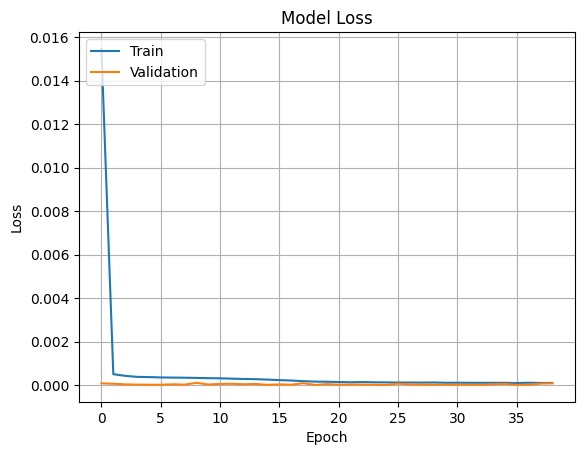

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16400\4217685152.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


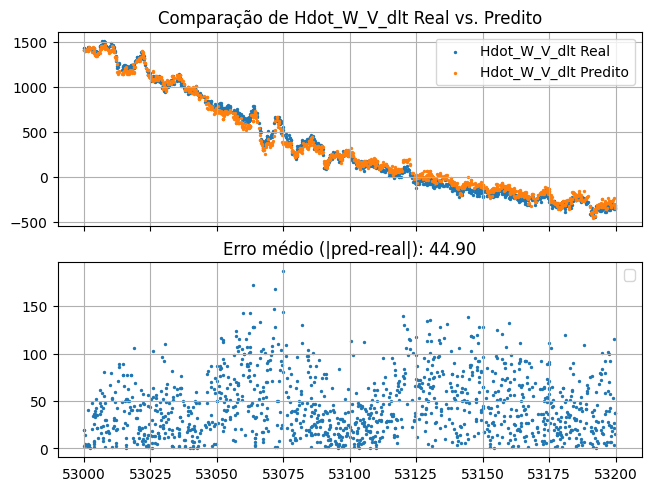

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 3s 757us/step


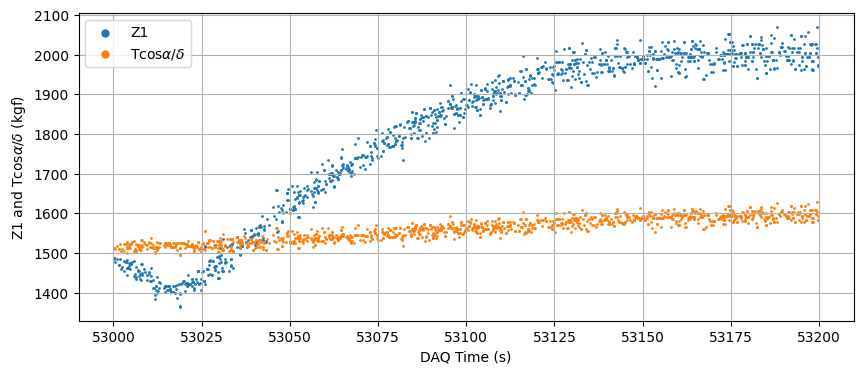

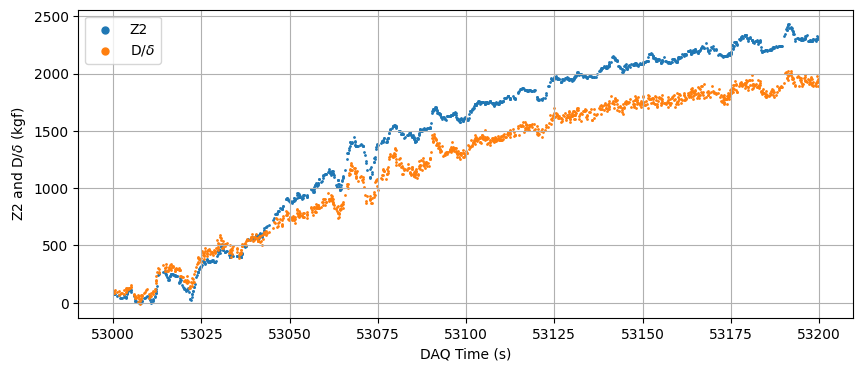

In [17]:
neuronio = 50
camada = 10
lambda_mono = 0.0
lambda_anchor = 0.01
anchor_fraction = 0.05
teste_rapido(neuronio, camada, lambda_mono, lambda_anchor, anchor_fraction)

[]

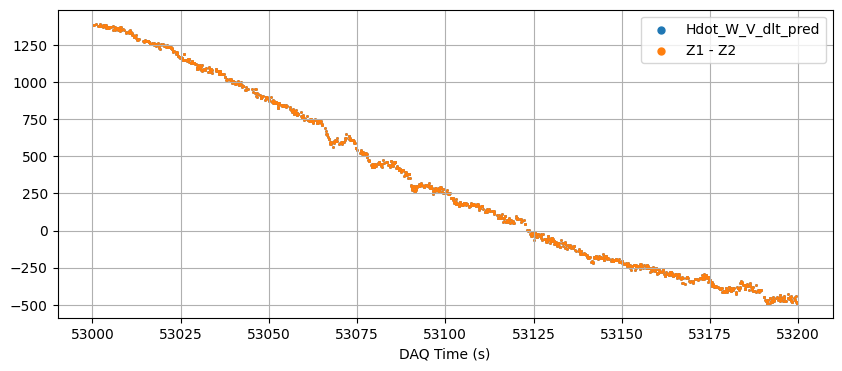

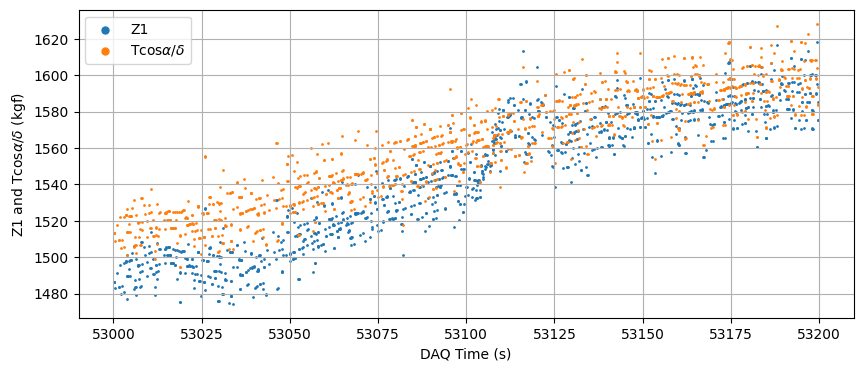

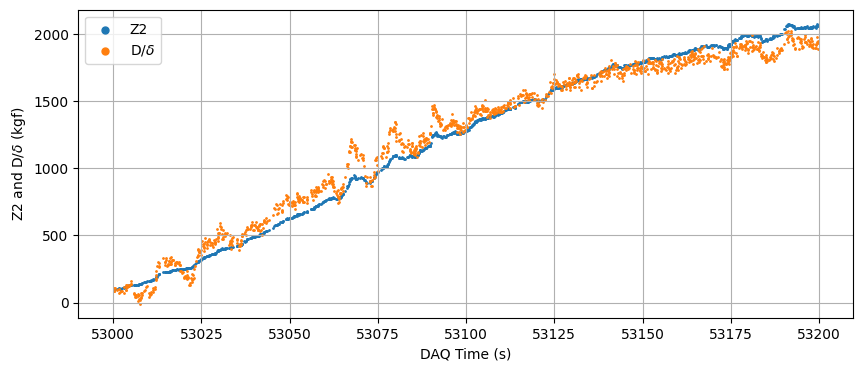

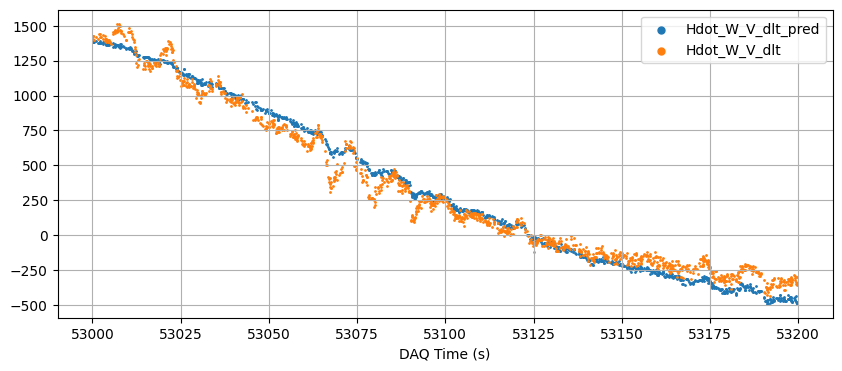

In [59]:
# k = min(min(grupo['Z1']), min(grupo['Z2']))
# grupo['Z1'], grupo['Z2'] = (
#     grupo['Z1'] - k + (grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1'] - grupo['Z2'])).mean(),
#     grupo['Z2'] - k
# )
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'] + (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean(), s=dot_size, label='Hdot_W_V_dlt_pred')
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1'] - grupo['Z2'] + (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean(), s=dot_size, label='Z1 - Z2')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

# --- linha 2: Z1 vs Tn_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z1']+ (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean() + 100, s=dot_size, label='Z1')
plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()


# --- linha 3: Z2 vs D_dlt ---
plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Z2'] + + 100, s=dot_size, label='Z2')
plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')
plt.legend(markerscale=5); plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()

plt.figure(figsize=(10, 4))
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'] + (grupo['Hdot_W_V_dlt'] - grupo['Hdot_W_V_dlt_pred']).mean(), s=dot_size, label='Hdot_W_V_dlt_pred')
dy = 0
plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'] + dy, s=dot_size, label='Hdot_W_V_dlt')
# plt.scatter(grupo['TEMPO_SAD'], (grupo['Tn_dlt'] - grupo['D_dlt']), s=dot_size, label=r'Tcos$\alpha$/$\delta$ - D/$\delta$')
plt.legend(markerscale=5); plt.xlabel('DAQ Time (s)'); plt.grid()
plt.plot()
